# 10 · Economía y econometría

Los economistas usan Python para contrastar teorías con datos y para hacer previsiones. **statsmodels** ofrece
las herramientas econométricas (regresión con errores estándar adecuados, modelos de series temporales,
contrastes estadísticos) sobre pandas. Este módulo trabaja con cincuenta años de datos macroeconómicos de
Estados Unidos.

**Aprenderás**
1. Convertir niveles en tasas de crecimiento y manejar fechas trimestrales
2. Contrastar una ley económica con una regresión: la ley de Okun (producción y desempleo)
3. Leer una regresión con honestidad: coeficientes, intervalos de confianza, errores estándar robustos, revisión de residuos
4. Prever el crecimiento del PIB con un modelo ARIMA y compararlo con previsiones ingenuas mediante un backtest adecuado

## 1. Los datos
`macrodata` viene con statsmodels: series trimestrales de Estados Unidos de 1959 a 2009, que incluyen el PIB
real, la tasa de desempleo, la inflación y los tipos de interés.

In [1]:
import numpy as np, pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

raw = sm.datasets.macrodata.load_pandas().data
raw.index = pd.PeriodIndex.from_fields(year=raw["year"].astype(int), quarter=raw["quarter"].astype(int), freq="Q")
print(sm.datasets.macrodata.NOTE.split("Number of Variables")[0].strip()[:400])
raw[["realgdp", "unemp", "infl", "tbilrate"]].tail()

::
    Number of Observations - 203


,realgdp,unemp,infl,tbilrate
2008Q3,13324.600,6.0,-3.16,1.17
2008Q4,13141.920,6.9,-8.79,0.12
2009Q1,12925.410,8.1,0.94,0.22
2009Q2,12901.504,9.2,3.37,0.18
2009Q3,12990.341,9.6,3.56,0.12


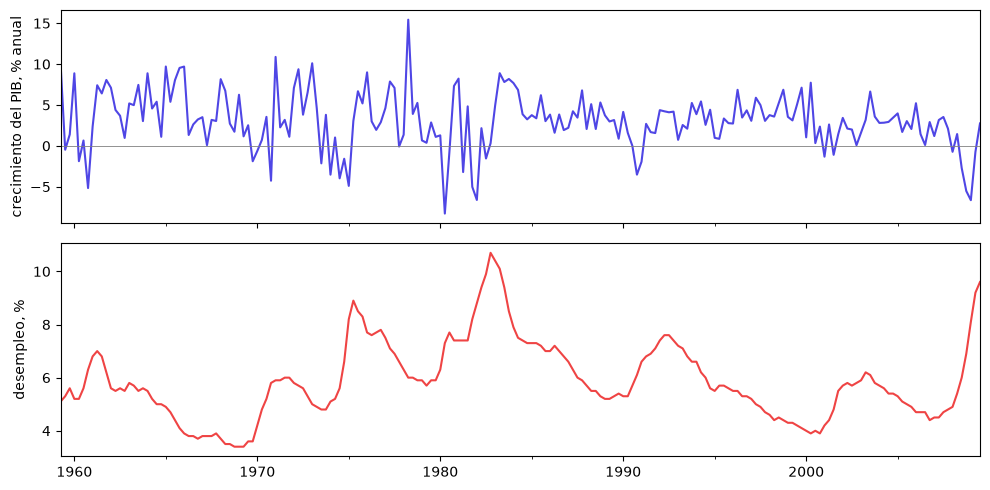

,gdp_growth,unemp,d_unemp,infl
count,202.00,202.00,202.00,202.00
mean,3.10,5.89,0.02,3.98
std,3.52,1.46,0.34,3.25
min,-8.28,3.40,-0.90,-8.79
25%,1.34,4.90,-0.20,2.28
50%,3.06,5.65,0.00,3.24
75%,5.09,6.80,0.10,4.98
max,15.43,10.70,1.60,14.62


In [2]:
df = pd.DataFrame({
    "gdp_growth": 400 * np.log(raw["realgdp"]).diff(),     # crecimiento anualizado en % (diferencia logarítmica)
    "unemp": raw["unemp"],
    "d_unemp": raw["unemp"].diff(),                        # cambio de la tasa de desempleo, en puntos
    "infl": raw["infl"],
}).dropna()

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
df["gdp_growth"].plot(ax=ax[0], color="#4f46e5"); ax[0].axhline(0, color="grey", lw=.6); ax[0].set_ylabel("crecimiento del PIB, % anual")
df["unemp"].plot(ax=ax[1], color="#ef4444"); ax[1].set_ylabel("desempleo, %")
plt.tight_layout(); plt.show()
df.describe().round(2)

## 2. La ley de Okun
Arthur Okun observó en 1962 que, cuando la producción crece más rápido que su ritmo normal, el desempleo baja.
En forma de regresión: $\Delta u_t = \alpha + \beta\, g_t + \varepsilon_t$, donde $g_t$ es el crecimiento del
PIB. La "regla práctica" de Okun espera un $\beta$ de entre $-0.3$ y $-0.5$ (por año), y $-\alpha/\beta$ es la
tasa de crecimiento que mantiene estable el desempleo.

In [3]:
X = sm.add_constant(df["gdp_growth"])
okun = sm.OLS(df["d_unemp"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})   # robusto a la autocorrelación
print(okun.summary().tables[1])
alpha, beta = okun.params
print(f"\nR² = {okun.rsquared:.2f}. Cada punto adicional de crecimiento anualizado reduce el desempleo en "
      f"{-beta:.3f} puntos por trimestre (~{-4 * beta:.2f} al año).")
print(f"Crecimiento necesario solo para mantener estable el desempleo: {-alpha / beta:.1f}% al año.")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2271      0.042      5.467      0.000       0.146       0.309
gdp_growth    -0.0671      0.009     -7.788      0.000      -0.084      -0.050

R² = 0.47. Cada punto adicional de crecimiento anualizado reduce el desempleo en 0.067 puntos por trimestre (~0.27 al año).
Crecimiento necesario solo para mantener estable el desempleo: 3.4% al año.


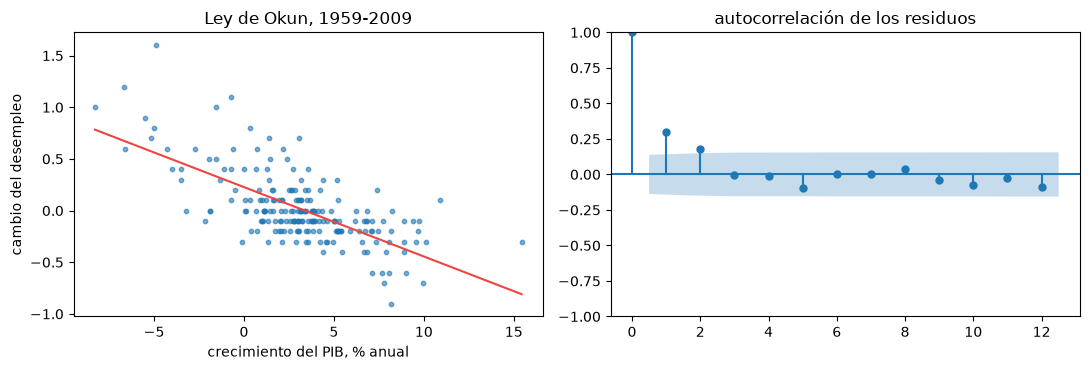

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(df["gdp_growth"], df["d_unemp"], s=10, alpha=.6)
xs = np.linspace(df["gdp_growth"].min(), df["gdp_growth"].max(), 50)
ax[0].plot(xs, alpha + beta * xs, color="#ef4444"); ax[0].set_xlabel("crecimiento del PIB, % anual"); ax[0].set_ylabel("cambio del desempleo")
ax[0].set_title("Ley de Okun, 1959-2009")
resid = okun.resid
sm.graphics.tsa.plot_acf(resid, lags=12, ax=ax[1]); ax[1].set_title("autocorrelación de los residuos")
plt.tight_layout(); plt.show()

La relación es fuerte y el signo es exactamente el que predice la teoría. Los residuos están autocorrelacionados
(el desempleo se ajusta a lo largo de varios trimestres), y por eso los errores estándar de arriba son HAC
(consistentes con heterocedasticidad y autocorrelación): los errores ordinarios exagerarían la precisión.

**¿Es estable la ley en el tiempo?** Una comprobación rápida: estimarla en cada década por separado.

In [5]:
rows = []
for start in range(1960, 2010, 10):
    d = df[(df.index.year >= start) & (df.index.year < start + 10)]
    fit = sm.OLS(d["d_unemp"], sm.add_constant(d["gdp_growth"])).fit()
    lo, hi = fit.conf_int().loc["gdp_growth"]
    rows.append(dict(decade=f"{start}s", beta=fit.params["gdp_growth"], ci_low=lo, ci_high=hi, quarters=len(d)))
pd.DataFrame(rows).set_index("decade").round(3)

,beta,ci_low,ci_high,quarters
decade,,,,
1960s,-0.045,-0.064,-0.026,40
1970s,-0.060,-0.084,-0.035,40
1980s,-0.083,-0.103,-0.063,40
1990s,-0.050,-0.076,-0.024,40
2000s,-0.094,-0.124,-0.063,39


## 3. Prever el crecimiento del PIB
Un modelo ARIMA predice una serie a partir de su propio pasado. Para saber si sirve, lo comparamos con dos
previsiones ingenuas en un **backtest con origen móvil**: en cada trimestre a partir de 1990 se ajusta solo con
el pasado, se prevé el trimestre siguiente y se avanza.

In [6]:
import warnings
from statsmodels.tsa.arima.model import ARIMA
warnings.filterwarnings("ignore")

y = df["gdp_growth"].astype(float).reset_index(drop=True)
dates = df.index
start = int(np.where(dates.year == 1990)[0][0])
preds = {"ARIMA(1,0,1)": [], "media histórica": [], "último valor": []}
actual = []
for t in range(start, len(y)):
    past = y.iloc[:t]
    preds["ARIMA(1,0,1)"].append(ARIMA(past, order=(1, 0, 1)).fit().forecast(1).iloc[0])
    preds["media histórica"].append(past.mean())
    preds["último valor"].append(past.iloc[-1])
    actual.append(y.iloc[t])
actual = np.array(actual)
scores = pd.DataFrame({k: {"MAE": np.mean(np.abs(np.array(v) - actual)), "RMSE": np.sqrt(np.mean((np.array(v) - actual) ** 2))}
                       for k, v in preds.items()}).T.round(3)
print(f"{len(actual)} previsiones a un trimestre vista, 1990-2009")
scores

79 previsiones a un trimestre vista, 1990-2009


,MAE,RMSE
"ARIMA(1,0,1)",1.739,2.347
media histórica,1.892,2.691
último valor,2.132,2.654


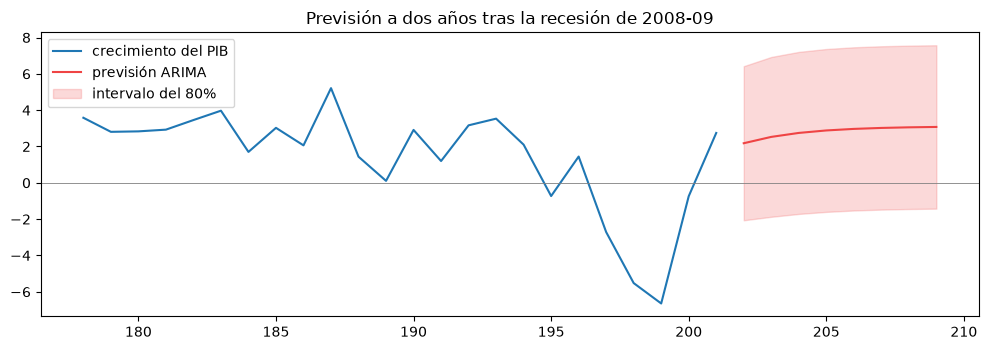

In [7]:
fit = ARIMA(y, order=(1, 0, 1)).fit()
fc = fit.get_forecast(8)
ci = fc.conf_int(alpha=0.2)
hist = y.iloc[-24:]
plt.figure(figsize=(10, 3.6))
plt.plot(range(len(y) - 24, len(y)), hist, label="crecimiento del PIB")
fx = range(len(y), len(y) + 8)
plt.plot(fx, fc.predicted_mean, color="#ef4444", label="previsión ARIMA")
plt.fill_between(fx, ci.iloc[:, 0], ci.iloc[:, 1], color="#ef4444", alpha=.2, label="intervalo del 80%")
plt.axhline(0, color="grey", lw=.6); plt.legend(); plt.title("Previsión a dos años tras la recesión de 2008-09"); plt.tight_layout(); plt.show()

**Leerlo con honestidad.** ARIMA supera a "repetir el último trimestre", pero solo mejora ligeramente a la media
histórica: el crecimiento trimestral del PIB es casi impredecible a partir de su propio pasado. La previsión
posterior a 2009 vuelve a la media en pocos trimestres y el intervalo es amplio. La previsión macroeconómica
seria añade otra información (encuestas, mercados financieros, indicadores adelantados), que es justo para lo
que sirven los modelos multivariantes como los VAR y los modelos de factores dinámicos de statsmodels.

## Bibliotecas que conviene conocer
| Área | Bibliotecas |
|---|---|
| econometría, series temporales | statsmodels, linearmodels (datos de panel, variables instrumentales), arch (volatilidad) |
| previsión | statsmodels, sktime, Darts, Prophet |
| inferencia causal | DoWhy, EconML, DoubleML |
| datos económicos | pandas-datareader, fredapi (datos de la Reserva Federal), wbgapi (Banco Mundial), sdmx1 (oficinas estadísticas) |
| finanzas cuantitativas | QuantLib, PyPortfolioOpt, vectorbt |

## Ejercicios
1. Estima una curva de Phillips: regresa el cambio de la inflación sobre la tasa de desempleo. ¿Es estable entre décadas?
2. Añade el crecimiento del PIB retardado a la regresión de Okun (`df["gdp_growth"].shift(1)`). ¿Mejora el R²?
3. Amplía el backtest a previsiones a cuatro trimestres vista. ¿Sigue ARIMA superando a la media?